In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import lightgbm as lgb
import shap

print("Ruta del entorno Python:", sys.executable)
print(f"Pandas: {pd.__version__} | Scikit-Learn: {sklearn.__version__} | XGBoost: {xgb.__version__}")

# Cargar el dataset para verificar lectura
df = pd.read_csv('Telco-Customer-Churn.csv')
print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head(3)

Ruta del entorno Python: c:\DiplomaturaCD\TP_Final_Churn_UTN\.venv\Scripts\python.exe
Pandas: 3.1.0 | Scikit-Learn: 1.9.1 | XGBoost: 3.4.1
Dataset cargado con éxito: 7043 filas y 21 columnas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


# Proyecto Final Integrador: Predicción del Abandono de Clientes (Churn) en Telecomunicaciones
**Diplomatura en Ciencia de Datos y Análisis Avanzado - UTN.BA**

### Metodología CRISP-DM y Enfoque de Negocio
* **Problema de Negocio:** Identificar de manera anticipada a los clientes con mayor probabilidad de abandonar el servicio (*churn*) para que las áreas de Retención, CRM y Marketing prioricen sus recursos de contacto.
* **Ajuste Metodológico (Entrega Final):** Un modelo predictivo estima probabilidades de baja y permite **priorizar acciones**, pero no reduce la tasa de churn por sí solo (lo cual requiere ejecutar una campaña comercial y medir su efecto incremental mediante pruebas A/B). Dado que el dataset no incluye resultados post-campaña, el **KPI operativo del modelo** se define como la **Capacidad de Concentración de Abandonos en el Top 20% de Mayor Riesgo (Recall @ Top 20% y Precision @ Top 20%)**, respondiendo a la pregunta de negocio: *"Si Retención puede contactar al 20% de la cartera, ¿cuántos abandonos reales logra concentrar allí?"*

In [2]:
# ==============================================================================
# FASE 2 CRISP-DM: AUDITORÍA DE CALIDAD DE DATOS Y LIMPIEZA
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Control de filas duplicadas y customerID repetidos
dup_rows = df.duplicated().sum()
dup_ids = df['customerID'].duplicated().sum()

# 2. Revisión de TotalCharges (espacios en blanco en clientes con antigüedad 0)
tc_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
nulos_tc = tc_numeric.isna().sum()
tenure_nulos = df.loc[tc_numeric.isna(), 'tenure'].unique()

print(f"1. Duplicados -> Filas: {dup_rows} | customerID: {dup_ids}")
print(f"2. TotalCharges vacíos: {nulos_tc} casos ({nulos_tc/len(df)*100:.2f}%), todos con tenure = {tenure_nulos}")

# Aplicación de limpieza definida en Pre-entrega
df_clean = df.copy()
df_clean['TotalCharges'] = tc_numeric.fillna(0.0)
df_clean['Churn_bin'] = (df_clean['Churn'] == 'Yes').astype(int)

# 3. Control de Outliers mediante criterio IQR (1.5 * IQR) en las 3 variables numéricas clave
num_cols_base = ['tenure', 'MonthlyCharges', 'TotalCharges']
resumen_calidad = []

for col in num_cols_base:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df_clean[col] < (q1 - 1.5 * iqr)) | (df_clean[col] > (q3 + 1.5 * iqr))).sum()
    resumen_calidad.append({
        'Variable': col,
        'Media': round(df_clean[col].mean(), 2),
        'Mediana': round(df_clean[col].median(), 2),
        'Desv_Std': round(df_clean[col].std(), 2),
        'Min': df_clean[col].min(),
        'Max': df_clean[col].max(),
        'Outliers_IQR': outliers
    })

print("\n3. Resumen Estadístico y Control de Outliers IQR:")
display(pd.DataFrame(resumen_calidad))

1. Duplicados -> Filas: 0 | customerID: 0
2. TotalCharges vacíos: 11 casos (0.16%), todos con tenure = [0]

3. Resumen Estadístico y Control de Outliers IQR:


,Variable,Media,Mediana,Desv_Std,Min,Max,Outliers_IQR
0,tenure,32.37,29.00,24.56,0.00,72.00,0
1,MonthlyCharges,64.76,70.35,30.09,18.25,118.75,0
2,TotalCharges,2279.73,1394.55,2266.79,0.00,8684.80,0


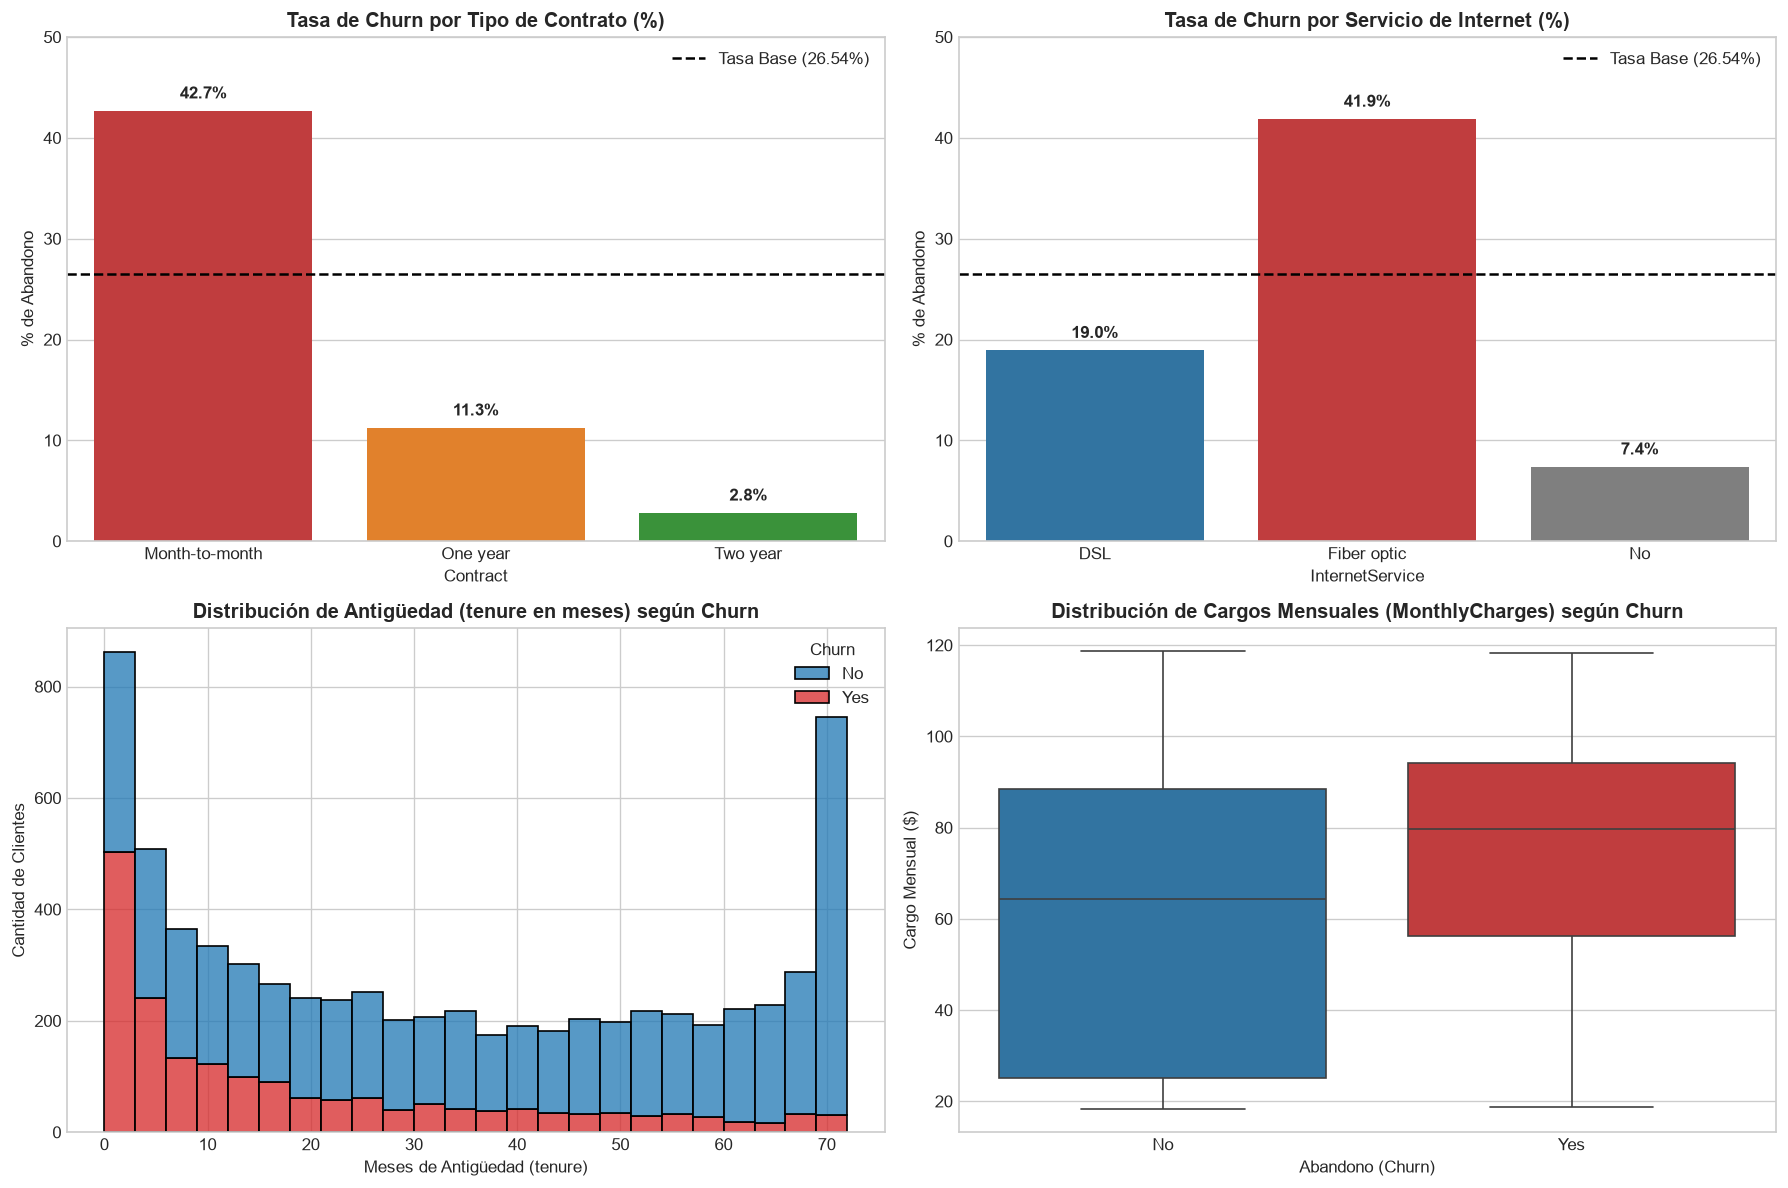

In [3]:
# ==============================================================================
# ANÁLISIS EXPLORATORIO DE DATOS (EDA) - FACTORES CLAVE DE ABANDONO
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=120)
tasa_base = df_clean['Churn_bin'].mean() * 100

# 1. Churn por Tipo de Contrato
ax1 = axes[0, 0]
contract_churn = df_clean.groupby('Contract')['Churn_bin'].mean().mul(100).reset_index()
sns.barplot(data=contract_churn, x='Contract', y='Churn_bin', hue='Contract',
            palette=['#d62728', '#ff7f0e', '#2ca02c'], ax=ax1, legend=False)
ax1.axhline(tasa_base, color='black', linestyle='--', label=f'Tasa Base ({tasa_base:.2f}%)')
for i, v in enumerate(contract_churn['Churn_bin']):
    ax1.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold')
ax1.set_title('Tasa de Churn por Tipo de Contrato (%)', fontweight='bold')
ax1.set_ylim(0, 50)
ax1.set_ylabel('% de Abandono')
ax1.legend()

# 2. Churn por Servicio de Internet
ax2 = axes[0, 1]
internet_churn = df_clean.groupby('InternetService')['Churn_bin'].mean().mul(100).reset_index()
sns.barplot(data=internet_churn, x='InternetService', y='Churn_bin', hue='InternetService',
            palette=['#1f77b4', '#d62728', '#7f7f7f'], ax=ax2, legend=False)
ax2.axhline(tasa_base, color='black', linestyle='--', label=f'Tasa Base ({tasa_base:.2f}%)')
for i, v in enumerate(internet_churn['Churn_bin']):
    ax2.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold')
ax2.set_title('Tasa de Churn por Servicio de Internet (%)', fontweight='bold')
ax2.set_ylim(0, 50)
ax2.set_ylabel('% de Abandono')
ax2.legend()

# 3. Distribución de Antigüedad (tenure) según Churn
ax3 = axes[1, 0]
sns.histplot(data=df_clean, x='tenure', hue='Churn', multiple='stack',
             palette={'No': '#1f77b4', 'Yes': '#d62728'}, bins=24, ax=ax3)
ax3.set_title('Distribución de Antigüedad (tenure en meses) según Churn', fontweight='bold')
ax3.set_xlabel('Meses de Antigüedad (tenure)')
ax3.set_ylabel('Cantidad de Clientes')

# 4. Cargos Mensuales (MonthlyCharges) según Churn
ax4 = axes[1, 1]
sns.boxplot(data=df_clean, x='Churn', y='MonthlyCharges', hue='Churn',
            palette={'No': '#1f77b4', 'Yes': '#d62728'}, ax=ax4, legend=False)
ax4.set_title('Distribución de Cargos Mensuales (MonthlyCharges) según Churn', fontweight='bold')
ax4.set_xlabel('Abandono (Churn)')
ax4.set_ylabel('Cargo Mensual ($)')

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# FASE 3 CRISP-DM: INGENIERÍA DE VARIABLES (FEATURE ENGINEERING)
# ==============================================================================
df_fe = df_clean.copy()

# 1. Cantidad total de servicios adicionales contratados (0 a 6)
servicios_extra = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
                   'TechSupport', 'StreamingTV', 'StreamingMovies']
df_fe['cant_servicios_adicionales'] = (df_fe[servicios_extra] == 'Yes').sum(axis=1)

# 2. Indicador de cliente de internet "Sin Blindaje Técnico" (sin seguridad online ni soporte técnico)
df_fe['sin_blindaje_tecnico'] = (
    (df_fe['InternetService'] != 'No') & 
    (df_fe['OnlineSecurity'] == 'No') & 
    (df_fe['TechSupport'] == 'No')
).astype(int)

# 3. Presión tarifaria temprana (Cargo mensual relativo a los meses de antigüedad)
df_fe['ratio_cargo_antiguedad'] = df_fe['MonthlyCharges'] / (df_fe['tenure'] + 1)

print("Comparativa de las nuevas variables según Churn (Promedio):")
display(df_fe.groupby('Churn')[['cant_servicios_adicionales', 'sin_blindaje_tecnico', 'ratio_cargo_antiguedad']].mean().round(2))

Comparativa de las nuevas variables según Churn (Promedio):


,cant_servicios_adicionales,sin_blindaje_tecnico,ratio_cargo_antiguedad
Churn,,,
No,2.14,0.25,3.61
Yes,1.77,0.67,11.75


In [5]:
# ==============================================================================
# REVISIÓN DE LA VARIABLE ratio_cargo_antiguedad (observación del docente)
# ==============================================================================
# ratio = MonthlyCharges / (tenure + 1). Al dividir por la antigüedad, los clientes nuevos
# obtienen valores muy altos aunque paguen poco. Verificamos qué mide realmente.
from scipy.stats import spearmanr

rho_tenure, _ = spearmanr(df_fe['ratio_cargo_antiguedad'], df_fe['tenure'])
rho_cargo, _ = spearmanr(df_fe['ratio_cargo_antiguedad'], df_fe['MonthlyCharges'])
print(f"Correlación de Spearman del ratio con tenure:         {rho_tenure:.2f}")
print(f"Correlación de Spearman del ratio con MonthlyCharges: {rho_cargo:.2f}")

tramos_ten = pd.cut(df_fe['tenure'], bins=[-1, 1, 6, 12, 24, 48, 72],
                    labels=['0-1', '2-6', '7-12', '13-24', '25-48', '49-72'])
display(df_fe.groupby(tramos_ten, observed=False).agg(
    Clientes=('tenure', 'size'),
    Mediana_ratio=('ratio_cargo_antiguedad', 'median'),
    Mediana_cargo_mensual=('MonthlyCharges', 'median'),
    Tasa_churn_pct=('Churn_bin', lambda x: round(x.mean() * 100, 1))
).round(2))
print("Conclusión: el ratio está dominado por la antigüedad (un cliente de 0-1 mes que paga 20 USD")
print("tiene un ratio mayor que uno de 2 años que paga 110 USD). Se interpreta como un indicador de")
print("'cliente nuevo' y no como una medida de presión de precio.")

Correlación de Spearman del ratio con tenure:         -0.83
Correlación de Spearman del ratio con MonthlyCharges: 0.24


,Clientes,Mediana_ratio,Mediana_cargo_mensual,Tasa_churn_pct
tenure,,,,
0-1,624,24.90,49.70,60.9
2-6,857,13.12,60.90,47.1
7-12,705,6.12,64.95,35.9
13-24,1024,3.36,66.40,28.7
25-48,1594,1.92,72.90,20.4
49-72,2239,1.26,82.50,9.5


Conclusión: el ratio está dominado por la antigüedad (un cliente de 0-1 mes que paga 20 USD
tiene un ratio mayor que uno de 2 años que paga 110 USD). Se interpreta como un indicador de
'cliente nuevo' y no como una medida de presión de precio.


## Fase 4 - Modelado: protocolo de selección (corrección de la reentrega)

**Transparencia sobre la versión anterior:** en la primera entrega el modelo final (Random Forest) se eligió comparando métricas sobre el conjunto de prueba (holdout). Eso es incorrecto: el test debe usarse una sola vez, para medir el modelo ya elegido. En esta versión el test ya había sido consultado, por lo que lo declaramos explícitamente.

**Protocolo corregido:**
1. Todas las métricas de comparación (Recall, Precision, F1, ROC-AUC, PR-AUC, Recall y Precision en el Top 20%) se calculan **solo con validación cruzada estratificada de 5 folds sobre el entrenamiento**. Para el Top 20% también se calcula el ranking con las probabilidades *out-of-fold* de `cross_val_predict`.
2. **Criterio de selección (fijado antes de ver los resultados de CV):** se elige el modelo con mayor PR-AUC promedio en CV. Si otro modelo queda a menos de un desvío estándar de ese mejor valor, se considera empatado y se elige **el más simple** (orden de simplicidad: Regresión Logística < Árbol < Random Forest < XGBoost). Entre dos variantes igual de simples, se prefiere la de mayor Recall en CV, porque la prioridad de negocio es detectar bajas.
3. El modelo elegido se entrena con todo el entrenamiento y se evalúa **una única vez** en el test. Se reporta lo que dé.

In [6]:
# ==============================================================================
# FASE 4 CRISP-DM: COMPARACIÓN DE MODELOS SOLO CON VALIDACIÓN CRUZADA
# ==============================================================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, make_scorer)
import xgboost as xgb

# 1. Conjuntos base y con feature engineering + partición holdout estratificada 80/20
X_base = df_clean.drop(columns=['customerID', 'Churn', 'Churn_bin'])
X_fe = df_fe.drop(columns=['customerID', 'Churn', 'Churn_bin'])
y = df_clean['Churn_bin']
X_train_b, X_test_b, y_train, y_test = train_test_split(X_base, y, test_size=0.20, stratify=y, random_state=42)
X_train_fe, X_test_fe, _, _ = train_test_split(X_fe, y, test_size=0.20, stratify=y, random_state=42)

num_cols_b = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols_b = [c for c in X_base.columns if c not in num_cols_b]
prep_base = ColumnTransformer([('num', StandardScaler(), num_cols_b),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_b)])
num_cols_fe = num_cols_b + ['cant_servicios_adicionales', 'sin_blindaje_tecnico', 'ratio_cargo_antiguedad']
cat_cols_fe = [c for c in X_fe.columns if c not in num_cols_fe]
prep_fe = ColumnTransformer([('num', StandardScaler(), num_cols_fe),
                             ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_fe)])
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

# 2. Métricas del Top 20% como scorers (se calculan dentro de cada fold de validación)
def recall_top20(y_true, y_score):
    k = int(round(len(y_true) * 0.20))
    idx = np.argsort(y_score)[::-1][:k]
    return np.asarray(y_true)[idx].sum() / np.sum(y_true)

def precision_top20(y_true, y_score):
    k = int(round(len(y_true) * 0.20))
    idx = np.argsort(y_score)[::-1][:k]
    return np.asarray(y_true)[idx].mean()

scoring = {'recall': 'recall', 'precision': make_scorer(precision_score, zero_division=0), 'f1': 'f1', 'roc_auc': 'roc_auc',
           'pr_auc': 'average_precision',
           'recall_top20': make_scorer(recall_top20, response_method='predict_proba'),
           'precision_top20': make_scorer(precision_top20, response_method='predict_proba')}

# 3. Experimentos: (nombre, clasificador, usa_FE, nivel de complejidad: menor = más simple)
experimentos = [
    ('1. Baseline (Dummy Mayoritaria)', DummyClassifier(strategy='most_frequent', random_state=42), False, 0),
    ('2. Reg. Logística Estándar', LogisticRegression(max_iter=1000, random_state=42), False, 1),
    ('3. Reg. Logística Balanceada', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), False, 1),
    ('4. Árbol de Decisión (max_depth=5, Bal.)', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42), True, 2),
    ('5. Random Forest Balanceado (con FE)', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42), True, 3),
    ('6. XGBoost Balanceado (con FE)', xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42), True, 4)
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
filas_cv, pipelines = [], {}
for nombre, clf, usa_fe, complejidad in experimentos:
    X_tr = X_train_fe if usa_fe else X_train_b
    pipe = Pipeline([('prep', prep_fe if usa_fe else prep_base), ('clf', clf)])
    pipelines[nombre] = (pipe, usa_fe)
    res = cross_validate(pipe, X_tr, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    oof = cross_val_predict(pipe, X_tr, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    fila = {'Modelo': nombre, 'Complejidad': complejidad}
    for m in scoring:
        fila[f'CV {m}'] = res[f'test_{m}'].mean()
        fila[f'CV {m} (desv)'] = res[f'test_{m}'].std()
    fila['OOF Recall Top20'] = recall_top20(y_train, oof)
    fila['OOF Precision Top20'] = precision_top20(y_train, oof)
    filas_cv.append(fila)

df_cv = pd.DataFrame(filas_cv)
cols_show = ['Modelo', 'CV recall', 'CV precision', 'CV f1', 'CV roc_auc', 'CV pr_auc', 'CV pr_auc (desv)',
             'CV recall_top20', 'CV precision_top20', 'OOF Recall Top20', 'OOF Precision Top20']
print("Tabla de comparación (solo entrenamiento, 5 folds). Métricas de clasificación con umbral 0,5.")
display(df_cv[cols_show].round(3))

Tabla de comparación (solo entrenamiento, 5 folds). Métricas de clasificación con umbral 0,5.


,Modelo,CV recall,CV precision,CV f1,CV roc_auc,CV pr_auc,CV pr_auc (desv),CV recall_top20,CV precision_top20,OOF Recall Top20,OOF Precision Top20
0,1. Baseline (Dummy Mayoritaria),0.000,0.000,0.000,0.500,0.265,0.000,0.199,0.264,0.197,0.262
1,2. Reg. Logística Estándar,0.544,0.652,0.592,0.846,0.661,0.019,0.506,0.672,0.508,0.673
2,3. Reg. Logística Balanceada,0.801,0.517,0.628,0.846,0.660,0.020,0.502,0.667,0.503,0.667
3,"4. Árbol de Decisión (max_depth=5, Bal.)",0.786,0.501,0.611,0.826,0.611,0.015,0.483,0.642,0.474,0.629
4,5. Random Forest Balanceado (con FE),0.777,0.532,0.631,0.848,0.664,0.020,0.504,0.670,0.504,0.668
5,6. XGBoost Balanceado (con FE),0.790,0.525,0.631,0.849,0.669,0.021,0.506,0.672,0.506,0.671


Mejor PR-AUC en CV: 6. XGBoost Balanceado (con FE) = 0.669 (desvío 0.021)
Se consideran empatados los modelos con PR-AUC >= 0.649:
   - 2. Reg. Logística Estándar: PR-AUC 0.661 | Recall 0.544 | Complejidad 1
   - 3. Reg. Logística Balanceada: PR-AUC 0.660 | Recall 0.801 | Complejidad 1
   - 5. Random Forest Balanceado (con FE): PR-AUC 0.664 | Recall 0.777 | Complejidad 3
   - 6. XGBoost Balanceado (con FE): PR-AUC 0.669 | Recall 0.790 | Complejidad 4

==> MODELO ELEGIDO POR VALIDACIÓN CRUZADA: 3. Reg. Logística Balanceada
    (el más simple dentro del empate; entre las dos regresiones se prefiere la de mayor Recall en CV)


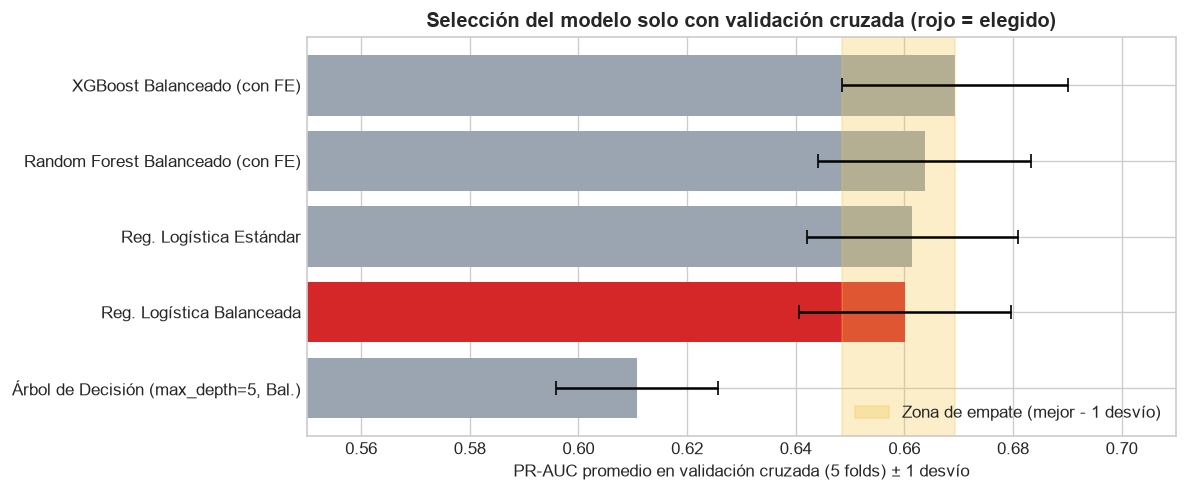

In [7]:
# ==============================================================================
# APLICACIÓN DEL CRITERIO DE SELECCIÓN ESCRITO DE ANTEMANO
# ==============================================================================
candidatos = df_cv[df_cv['Complejidad'] > 0].copy()            # se excluye el baseline
mejor = candidatos.loc[candidatos['CV pr_auc'].idxmax()]
umbral_empate = mejor['CV pr_auc'] - mejor['CV pr_auc (desv)']
empatados = candidatos[candidatos['CV pr_auc'] >= umbral_empate]

print(f"Mejor PR-AUC en CV: {mejor['Modelo']} = {mejor['CV pr_auc']:.3f} (desvío {mejor['CV pr_auc (desv)']:.3f})")
print(f"Se consideran empatados los modelos con PR-AUC >= {umbral_empate:.3f}:")
for _, r in empatados.iterrows():
    print(f"   - {r['Modelo']}: PR-AUC {r['CV pr_auc']:.3f} | Recall {r['CV recall']:.3f} | Complejidad {r['Complejidad']}")

mas_simples = empatados[empatados['Complejidad'] == empatados['Complejidad'].min()]
elegido = mas_simples.loc[mas_simples['CV recall'].idxmax()]
MODELO_FINAL = elegido['Modelo']
print(f"\n==> MODELO ELEGIDO POR VALIDACIÓN CRUZADA: {MODELO_FINAL}")
print("    (el más simple dentro del empate; entre las dos regresiones se prefiere la de mayor Recall en CV)")

# Gráfico: PR-AUC en CV con ±1 desvío y franja de empate
plot_df = candidatos.sort_values('CV pr_auc')
colores = ['#d62728' if m == MODELO_FINAL else '#9aa5b1' for m in plot_df['Modelo']]
plt.figure(figsize=(10, 4.2), dpi=120)
plt.barh([m.split('. ', 1)[1] for m in plot_df['Modelo']], plot_df['CV pr_auc'],
         xerr=plot_df['CV pr_auc (desv)'], color=colores, capsize=4)
plt.axvspan(umbral_empate, mejor['CV pr_auc'], color='#f2c94c', alpha=0.3, label='Zona de empate (mejor - 1 desvío)')
plt.xlim(0.55, 0.71); plt.xlabel('PR-AUC promedio en validación cruzada (5 folds) ± 1 desvío')
plt.title('Selección del modelo solo con validación cruzada (rojo = elegido)', fontweight='bold')
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

In [8]:
# ==============================================================================
# FASE 5 CRISP-DM: EVALUACIÓN ÚNICA DEL MODELO ELEGIDO EN EL TEST (HOLDOUT)
# ==============================================================================
pipe_final, usa_fe_final = pipelines[MODELO_FINAL]
X_tr_final = X_train_fe if usa_fe_final else X_train_b
X_te_final = X_test_fe if usa_fe_final else X_test_b
pipe_final.fit(X_tr_final, y_train)

y_pred = pipe_final.predict(X_te_final)
y_prob_final = pipe_final.predict_proba(X_te_final)[:, 1]

k_top20 = int(round(len(y_test) * 0.20))        # 282 clientes
total_churn_test = int(y_test.sum())             # 374 bajas reales
base_rate_test = y_test.mean()                   # 26,54%
top_idx = np.argsort(y_prob_final)[::-1][:k_top20]
bajas_top20 = int(y_test.iloc[top_idx].sum())
prec_top20 = y_test.iloc[top_idx].mean()

resultado_test = pd.DataFrame([{
    'Modelo': MODELO_FINAL,
    'Recall': recall_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred), 'ROC-AUC': roc_auc_score(y_test, y_prob_final),
    'PR-AUC': average_precision_score(y_test, y_prob_final),
    f'Bajas en Top 20% (de {k_top20})': bajas_top20,
    'Precision @ Top 20% (%)': prec_top20 * 100,
    'Recall @ Top 20% (%)': bajas_top20 / total_churn_test * 100,
    'Lift @ Top 20%': prec_top20 / base_rate_test}]).round(3)
display(resultado_test)

fila_cv = df_cv.set_index('Modelo').loc[MODELO_FINAL]
print("Comparación CV vs Test del modelo elegido (consistencia):")
print(f"   PR-AUC:        CV {fila_cv['CV pr_auc']:.3f}  |  Test {average_precision_score(y_test, y_prob_final):.3f}")
print(f"   Recall Top20:  CV {fila_cv['CV recall_top20']:.3f}  |  Test {bajas_top20 / total_churn_test:.3f}")

,Modelo,Recall,Precision,F1,ROC-AUC,PR-AUC,Bajas en Top 20% (de 282),Precision @ Top 20% (%),Recall @ Top 20% (%),Lift @ Top 20%
0,3. Reg. Logística Balanceada,0.783,0.504,0.614,0.842,0.633,186,65.957,49.733,2.485


Comparación CV vs Test del modelo elegido (consistencia):
   PR-AUC:        CV 0.660  |  Test 0.633
   Recall Top20:  CV 0.502  |  Test 0.497


In [9]:
# ==============================================================================
# TRADUCCIÓN A NEGOCIO: TABLA POR QUINTILES DEL MODELO ELEGIDO (TEST)
# ==============================================================================
df_ranking = pd.DataFrame({'Churn_Real': y_test.values, 'Prob_Churn': y_prob_final,
                           'MonthlyCharges': X_test_b['MonthlyCharges'].values,
                           'tenure': X_test_b['tenure'].values}
                         ).sort_values('Prob_Churn', ascending=False).reset_index(drop=True)
df_ranking['Tramo_Cartera'] = pd.qcut(df_ranking.index, q=5, labels=[
    'Quintil 1 (Top 0% - 20% Mayor Riesgo)', 'Quintil 2 (20% - 40%)', 'Quintil 3 (40% - 60%)',
    'Quintil 4 (60% - 80%)', 'Quintil 5 (80% - 100% Menor Riesgo)'])

tabla_quintiles = df_ranking.groupby('Tramo_Cartera', observed=False).agg(
    Clientes=('Churn_Real', 'count'), Bajas_reales=('Churn_Real', 'sum'),
    Tasa_churn_pct=('Churn_Real', lambda x: round(x.mean() * 100, 2))).reset_index()
tabla_quintiles['Bajas_acumuladas'] = tabla_quintiles['Bajas_reales'].cumsum()
tabla_quintiles['Recall_acumulado_pct'] = (tabla_quintiles['Bajas_acumuladas'] / total_churn_test * 100).round(2)
tabla_quintiles['Lift'] = (tabla_quintiles['Tasa_churn_pct'] / 100 / base_rate_test).round(2)

fmt = lambda v: f"{v:.2f}".replace('.', ',')
q1 = tabla_quintiles.iloc[0]
print(f"=== MODELO: {MODELO_FINAL} | 1.409 clientes y {total_churn_test} bajas reales en test ===")
print(f"Si Retención contacta al 20% de mayor riesgo ({q1['Clientes']} clientes):")
print(f"  * Acierta en el {fmt(q1['Tasa_churn_pct'])}% de los casos (vs {fmt(base_rate_test*100)}% al azar, lift {fmt(q1['Lift'])}x).")
print(f"  * Concentra {q1['Bajas_reales']} de las {total_churn_test} bajas ({fmt(q1['Recall_acumulado_pct'])}% del total).")
display(tabla_quintiles)

=== MODELO: 3. Reg. Logística Balanceada | 1.409 clientes y 374 bajas reales en test ===
Si Retención contacta al 20% de mayor riesgo (282 clientes):
  * Acierta en el 65,96% de los casos (vs 26,54% al azar, lift 2,48x).
  * Concentra 186 de las 374 bajas (49,73% del total).


,Tramo_Cartera,Clientes,Bajas_reales,Tasa_churn_pct,Bajas_acumuladas,Recall_acumulado_pct,Lift
0,Quintil 1 (Top 0% - 20% Mayor Riesgo),282,186,65.96,186,49.73,2.48
1,Quintil 2 (20% - 40%),282,105,37.23,291,77.81,1.40
2,Quintil 3 (40% - 60%),281,59,21.00,350,93.58,0.79
3,Quintil 4 (60% - 80%),282,21,7.45,371,99.20,0.28
4,Quintil 5 (80% - 100% Menor Riesgo),282,3,1.06,374,100.00,0.04


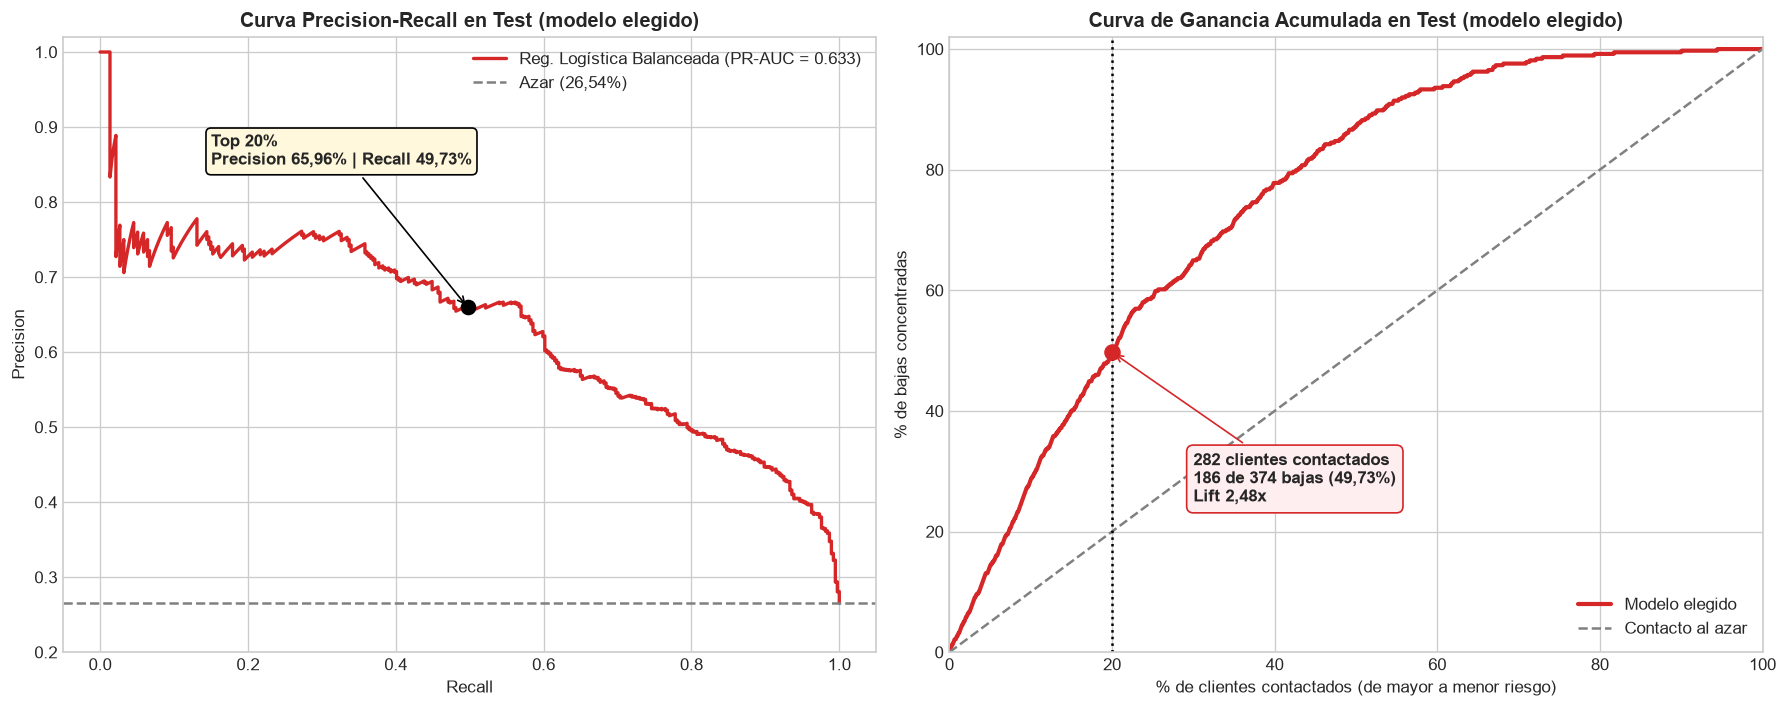

In [10]:
# ==============================================================================
# CURVAS DEL MODELO ELEGIDO EN TEST: PRECISION-RECALL Y GANANCIA ACUMULADA
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
recall_20 = bajas_top20 / total_churn_test

prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob_final)
axes[0].plot(rec_c, prec_c, color='#d62728', linewidth=2,
             label=f"{MODELO_FINAL.split('. ', 1)[1]} (PR-AUC = {average_precision_score(y_test, y_prob_final):.3f})")
axes[0].axhline(base_rate_test, color='gray', linestyle='--', label=f'Azar ({fmt(base_rate_test*100)}%)')
axes[0].scatter([recall_20], [prec_top20], color='black', zorder=5, s=70)
axes[0].annotate(f"Top 20%\nPrecision {fmt(prec_top20*100)}% | Recall {fmt(recall_20*100)}%",
                 xy=(recall_20, prec_top20), xytext=(0.15, 0.85), arrowprops=dict(arrowstyle='->'),
                 fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='#fff8dc', ec='black'))
axes[0].set_title('Curva Precision-Recall en Test (modelo elegido)', fontweight='bold')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision'); axes[0].set_ylim([0.2, 1.02]); axes[0].legend(loc='upper right')

# Curva de ganancia: el punto del 20% se marca exactamente en k = 282 clientes, igual que la tabla
pct_cartera = np.arange(1, len(df_ranking) + 1) / len(df_ranking) * 100
pct_bajas = df_ranking['Churn_Real'].cumsum() / total_churn_test * 100
x20 = k_top20 / len(df_ranking) * 100
axes[1].plot(pct_cartera, pct_bajas, color='#d62728', linewidth=2.5, label='Modelo elegido')
axes[1].plot([0, 100], [0, 100], color='gray', linestyle='--', label='Contacto al azar')
axes[1].axvline(x20, color='black', linestyle=':')
axes[1].scatter([x20], [recall_20 * 100], color='#d62728', zorder=5, s=80)
axes[1].annotate(f"{k_top20} clientes contactados\n{bajas_top20} de {total_churn_test} bajas ({fmt(recall_20*100)}%)\nLift {fmt(prec_top20/base_rate_test)}x",
                 xy=(x20, recall_20 * 100), xytext=(30, 25), arrowprops=dict(arrowstyle='->', color='#d62728'),
                 fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', fc='#ffeef0', ec='#d62728'))
axes[1].set_title('Curva de Ganancia Acumulada en Test (modelo elegido)', fontweight='bold')
axes[1].set_xlabel('% de clientes contactados (de mayor a menor riesgo)')
axes[1].set_ylabel('% de bajas concentradas'); axes[1].set_xlim([0, 100]); axes[1].set_ylim([0, 102]); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

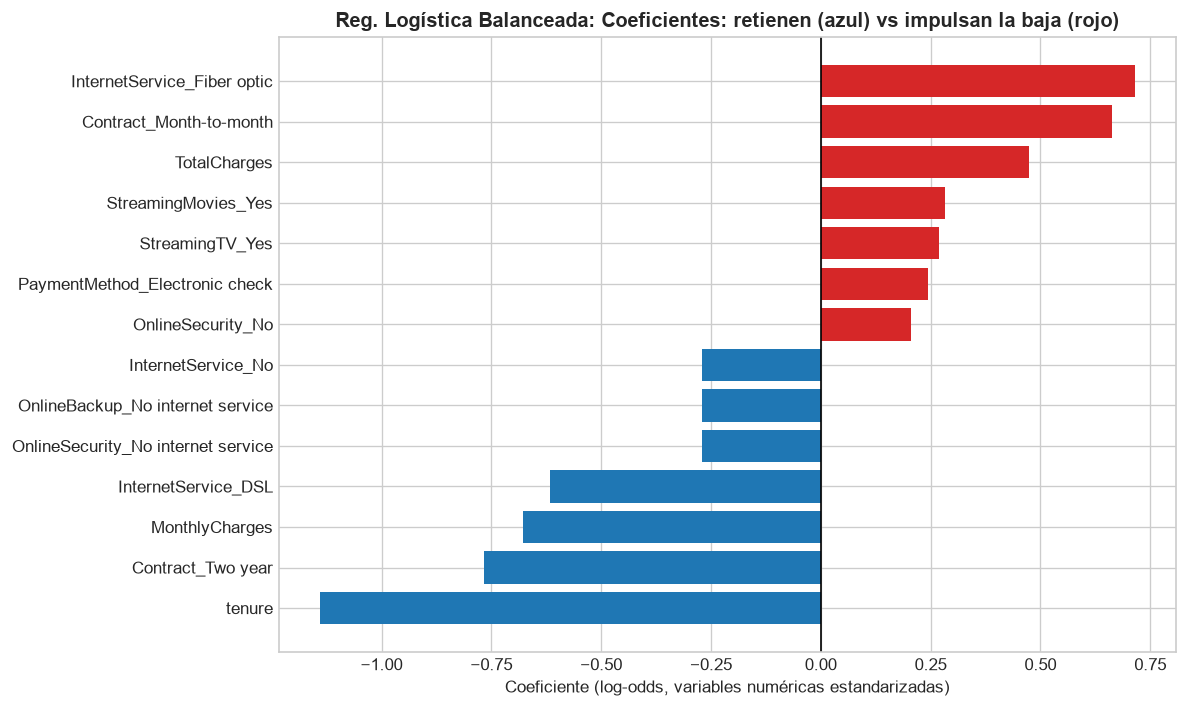

In [11]:
# ==============================================================================
# INTERPRETABILIDAD DEL MODELO ELEGIDO
# ==============================================================================
clf_final = pipe_final.named_steps['clf']
nombres = [n.replace('cat__', '').replace('num__', '') for n in pipe_final.named_steps['prep'].get_feature_names_out()]
if hasattr(clf_final, 'coef_'):
    coefs = pd.Series(clf_final.coef_[0], index=nombres).sort_values()
    top = pd.concat([coefs.head(7), coefs.tail(7)])
    titulo, eje = 'Coeficientes: retienen (azul) vs impulsan la baja (rojo)', 'Coeficiente (log-odds, variables numéricas estandarizadas)'
else:
    top = pd.Series(clf_final.feature_importances_, index=nombres).sort_values().tail(14)
    titulo, eje = 'Importancia de variables', 'Importancia relativa'
plt.figure(figsize=(10, 6), dpi=120)
plt.barh(top.index, top.values, color=['#1f77b4' if v < 0 else '#d62728' for v in top.values])
plt.axvline(0, color='black', linewidth=1)
plt.title(f"{MODELO_FINAL.split('. ', 1)[1]}: {titulo}", fontweight='bold'); plt.xlabel(eje)
plt.tight_layout(); plt.show()

## Anexo de negocio (sugerencias del docente)

Las dos celdas siguientes no intervienen en la selección del modelo: usan las predicciones del modelo ya elegido para ayudar a Retención a decidir **a quién llamar primero**.

In [12]:
# ==============================================================================
# FACTURACIÓN EN RIESGO POR NIVEL DE FACTURACIÓN Y ANTIGÜEDAD (TEST)
# ==============================================================================
df_ranking['En_Top20'] = df_ranking.index < k_top20
corte_baja, corte_alta = X_train_b['MonthlyCharges'].quantile([1/3, 2/3])   # cortes definidos en entrenamiento
df_ranking['Facturacion'] = pd.cut(df_ranking['MonthlyCharges'], [-np.inf, corte_baja, corte_alta, np.inf],
                                   labels=['Baja', 'Media', 'Alta'])
df_ranking['Antiguedad'] = pd.cut(df_ranking['tenure'], [-1, 12, 24, 72], labels=['0-12 meses', '13-24 meses', '25+ meses'])

seg = df_ranking.groupby(['Facturacion', 'Antiguedad'], observed=False).apply(lambda g: pd.Series({
    'Clientes': len(g),
    'Tasa_churn_real_pct': round(g['Churn_Real'].mean() * 100, 1) if len(g) else 0,
    'Clientes_en_Top20': int(g['En_Top20'].sum()),
    'Facturacion_mensual_Top20_USD': round(g.loc[g['En_Top20'], 'MonthlyCharges'].sum(), 0),
    'Facturacion_mensual_bajas_reales_USD': round(g.loc[g['Churn_Real'] == 1, 'MonthlyCharges'].sum(), 0)
}), include_groups=False).reset_index()
seg['Pct_facturacion_perdida_total'] = (seg['Facturacion_mensual_bajas_reales_USD'] /
                                        seg['Facturacion_mensual_bajas_reales_USD'].sum() * 100).round(1)
print(f"Cortes de facturación mensual (terciles del entrenamiento): baja <= {corte_baja:.2f} < media <= {corte_alta:.2f} < alta")
seg[['Clientes', 'Clientes_en_Top20']] = seg[['Clientes', 'Clientes_en_Top20']].astype(int)
display(seg.sort_values('Facturacion_mensual_bajas_reales_USD', ascending=False))

Cortes de facturación mensual (terciles del entrenamiento): baja <= 50.50 < media <= 84.22 < alta


,Facturacion,Antiguedad,Clientes,Tasa_churn_real_pct,Clientes_en_Top20,Facturacion_mensual_Top20_USD,Facturacion_mensual_bajas_reales_USD,Pct_facturacion_perdida_total
3,Media,0-12 meses,189,53.4,116,8594.0,7230.0,26.6
8,Alta,25+ meses,304,21.4,27,2637.0,6460.0,23.7
6,Alta,0-12 meses,67,65.7,61,5647.0,4106.0,15.1
7,Alta,13-24 meses,68,50.0,34,3167.0,3169.0,11.6
0,Baja,0-12 meses,193,36.3,18,563.0,2297.0,8.4
5,Media,25+ meses,233,12.4,4,317.0,2062.0,7.6
4,Media,13-24 meses,69,29.0,19,1475.0,1430.0,5.3
1,Baja,13-24 meses,69,8.7,3,143.0,247.0,0.9
2,Baja,25+ meses,217,2.3,0,0.0,214.0,0.8


In [13]:
# ==============================================================================
# ESCENARIOS SIMPLES DE COSTO DE CONTACTO VS. VALOR DEL CLIENTE RETENIDO (HIPOTÉTICOS)
# ==============================================================================
# Supuestos (no medidos en el dataset): valor de un cliente retenido = 12 meses de su cargo mensual;
# la acción retiene a una fracción "tasa de éxito" de las bajas contactadas; cada contacto cuesta "costo".
top = df_ranking.iloc[:k_top20]
valor_bajas_modelo = (top.loc[top['Churn_Real'] == 1, 'MonthlyCharges'] * 12).sum()
# Contactar 282 clientes al azar: en valor esperado se captura el 20% del valor de todas las bajas
valor_bajas_azar = (df_ranking.loc[df_ranking['Churn_Real'] == 1, 'MonthlyCharges'] * 12).sum() * (k_top20 / len(df_ranking))

filas = []
for costo in [5, 15, 30]:
    for exito in [0.10, 0.20, 0.30]:
        b_mod = exito * valor_bajas_modelo - costo * k_top20
        b_azar = exito * valor_bajas_azar - costo * k_top20
        filas.append({'Costo por contacto (USD)': costo, 'Tasa de éxito': f"{int(exito*100)}%",
                      'Beneficio neto con modelo (USD)': round(b_mod), 'Beneficio neto al azar (USD)': round(b_azar),
                      'Diferencia a favor del modelo (USD)': round(b_mod - b_azar)})
print(f"Contactando {k_top20} clientes. Valor anual de las bajas capturadas: modelo {valor_bajas_modelo:,.0f} USD | azar (esperado) {valor_bajas_azar:,.0f} USD")
display(pd.DataFrame(filas))

Contactando 282 clientes. Valor anual de las bajas capturadas: modelo 177,278 USD | azar (esperado) 65,362 USD


,Costo por contacto (USD),Tasa de éxito,Beneficio neto con modelo (USD),Beneficio neto al azar (USD),Diferencia a favor del modelo (USD)
0,5,10%,16318,5126,11192
1,5,20%,34046,11662,22383
2,5,30%,51773,18199,33575
3,15,10%,13498,2306,11192
4,15,20%,31226,8842,22383
5,15,30%,48953,15379,33575
6,30,10%,9268,-1924,11192
7,30,20%,26996,4612,22383
8,30,30%,44723,11149,33575


## Conclusiones, Acciones de Retención y Consideraciones Éticas

### 1. Selección del modelo
* La comparación se hizo **solo con validación cruzada**. XGBoost obtuvo el mayor PR-AUC en CV, pero Random Forest y las dos Regresiones Logísticas quedaron a menos de un desvío estándar: la diferencia no es distinguible del ruido entre folds.
* Aplicando el criterio fijado de antemano se eligió la **Regresión Logística Balanceada**: es la más simple, la más fácil de explicar a Retención y la de mayor Recall en CV (0,801).
* En la entrega anterior el test se había consultado para elegir Random Forest; lo corregimos y lo declaramos. Ahora el test se usó una sola vez, con el modelo ya elegido.

### 2. Valor de negocio sobre el Top 20%
* Contactando al 20% de mayor riesgo (282 clientes del test), el modelo encuentra **186 de las 374 bajas (49,73%)**, con una tasa de acierto de **65,96%** frente a 26,54% al azar (**lift 2,48x**). El resultado es consistente con la CV (Recall Top 20% de 50,2%).
* Las tablas de facturación en riesgo y de escenarios de costo permiten priorizar dentro de esa lista (por ejemplo, primero los clientes de facturación alta y antigüedad baja).

### 3. Hipótesis de acciones (a validar con grupo de control)
1. Migración contractual incentivada para clientes `Month-to-month` de alto riesgo.
2. Prueba bonificada de `OnlineSecurity` y `TechSupport` para clientes de `Fiber optic` sin estos servicios.
3. Incentivos para pasar de `Electronic check` a débito automático.
4. Programa de bienvenida para clientes nuevos (los primeros meses concentran el riesgo; `ratio_cargo_antiguedad` mide sobre todo esto).

### 4. Ética y privacidad
* Se excluye `customerID` del modelo; un despliegue en Argentina debe cumplir la **Ley N.º 25.326**.
* Auditar periódicamente los resultados por `gender` y `SeniorCitizen` para evitar tratos diferenciales injustificados.